# **SIZE RECOMMENDTIONS**

#### **IMPORTS**

In [1]:
# Utilities.

import zipfile
import re

# Data Processing.

import pandas as pd
import numpy as np

# Visualization.

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning.

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Save/Load Models
import joblib 

#### **COLLECTING DATA**

In [4]:
zip_path = "data/archive (1).zip"
extract_path = 'data/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted!")

Extracted!


In [5]:
data_1 = pd.read_json("data/renttherunway_final_data.json", lines= True)

In [6]:
print("data1 shape: ",data_1.shape)

data1 shape:  (192544, 15)


In [7]:
data_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192544 entries, 0 to 192543
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   fit             192544 non-null  object 
 1   user_id         192544 non-null  int64  
 2   bust size       174133 non-null  object 
 3   item_id         192544 non-null  int64  
 4   weight          162562 non-null  object 
 5   rating          192462 non-null  float64
 6   rented for      192534 non-null  object 
 7   review_text     192544 non-null  object 
 8   body type       177907 non-null  object 
 9   review_summary  192544 non-null  object 
 10  category        192544 non-null  object 
 11  height          191867 non-null  object 
 12  size            192544 non-null  int64  
 13  age             191584 non-null  float64
 14  review_date     192544 non-null  object 
dtypes: float64(2), int64(3), object(10)
memory usage: 22.0+ MB


In [8]:
data_1.columns.tolist()

['fit',
 'user_id',
 'bust size',
 'item_id',
 'weight',
 'rating',
 'rented for',
 'review_text',
 'body type',
 'review_summary',
 'category',
 'height',
 'size',
 'age',
 'review_date']

In [9]:
print(data_1.isnull().sum())

fit                   0
user_id               0
bust size         18411
item_id               0
weight            29982
rating               82
rented for           10
review_text           0
body type         14637
review_summary        0
category              0
height              677
size                  0
age                 960
review_date           0
dtype: int64


In [10]:
data_1['item_id'].duplicated().sum()

np.int64(186694)

#### **COPYING DATA**

In [11]:
df = data_1.copy()

#### **ANALYSING AND CORRECTING DATA**

In [12]:
# see values in body type.

df['body type'].value_counts()

body type
hourglass            55349
athletic             43667
pear                 22135
petite               22131
full bust            15006
straight & narrow    14742
apple                 4877
Name: count, dtype: int64

In [13]:
# dropping rows.

df = df.dropna(subset= ['body type', 'size', 'height', 'weight', 'age'])

In [14]:
# cleaning height.

def parse_height(h):
    if pd.isna(h):
        return np.nan

    match = re.match(r"(\d+)'\s*(\d+)\"", str(h))
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))
        return (feet * 12) + inches
    return np.nan

df['height_inches'] = df['height'].apply(parse_height)

In [15]:
# cleaning weight

def parse_weight(w):
    if pd.isna(w):
        return np.nan
    try:

        return float(str(w).replace('lbs', '').strip())
    except:
        return np.nan

df['weight_lbs'] = df['weight'].apply(parse_weight)

In [16]:
# Map the body types

body_type_map = {
    'petite': 'Petite',
    'hourglass': 'Average',
    'athletic': 'Average',
    'pear': 'Broad',
    'apple': 'Broad',
    'full_bust': 'Broad',
    'straight & narrow': 'Average'
}

df['mapped_body_type'] = df['body type'].map(body_type_map)

In [17]:
# dropping rows where the height and weight parsing failed.

df = df.dropna(subset=['height_inches', 'weight_lbs', 'mapped_body_type'])

In [19]:
df = df[df['fit'] == 'fit']
print("Shape after keeping only 'fit' rows:", df.shape)

Shape after keeping only 'fit' rows: (104492, 18)


In [20]:
def categorize_size (size):
    if size <= 6:
        return 'Small'
    elif size <= 12:
        return 'Medium'
    else:
        return 'Large'

df['size_category'] = df['size'].apply(categorize_size)

print("New Target Destribution: ")
print(df['size_category'].value_counts())

New Target Destribution: 
size_category
Medium    40271
Large     34805
Small     29416
Name: count, dtype: int64


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 104492 entries, 0 to 192543
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   fit               104492 non-null  object 
 1   user_id           104492 non-null  int64  
 2   bust size         100098 non-null  object 
 3   item_id           104492 non-null  int64  
 4   weight            104492 non-null  object 
 5   rating            104452 non-null  float64
 6   rented for        104484 non-null  object 
 7   review_text       104492 non-null  object 
 8   body type         104492 non-null  object 
 9   review_summary    104492 non-null  object 
 10  category          104492 non-null  object 
 11  height            104492 non-null  object 
 12  size              104492 non-null  int64  
 13  age               104492 non-null  float64
 14  review_date       104492 non-null  object 
 15  height_inches     104492 non-null  int64  
 16  weight_lbs        104492 

In [22]:
print("Data Cleaned! Final Shape: ", df.shape)
print("\nSample of clean data: ")
print(df[['age', 'height_inches', 'weight_lbs', 'mapped_body_type', 'size', 'fit']].head(11))

Data Cleaned! Final Shape:  (104492, 19)

Sample of clean data: 
     age  height_inches  weight_lbs mapped_body_type  size  fit
0   28.0             68       137.0          Average    14  fit
1   36.0             66       132.0          Average    12  fit
3   34.0             65       135.0            Broad     8  fit
4   27.0             69       145.0          Average    12  fit
5   45.0             68       138.0          Average     8  fit
6   27.0             63       112.0          Average     4  fit
9   33.0             63       114.0           Petite     1  fit
12  26.0             66       120.0          Average     8  fit
14  32.0             65       118.0          Average     2  fit
15  30.0             67       140.0          Average    20  fit
16  35.0             68       170.0            Broad    20  fit


#### **CORRELATION ANALYSIS**

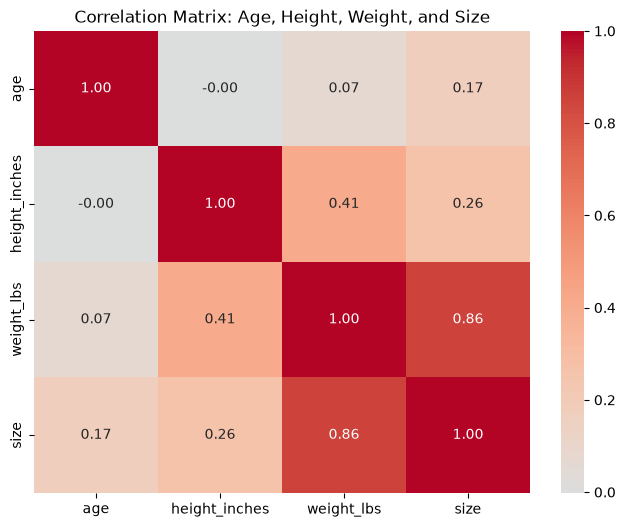

In [23]:
# Heatmap (Correlation matrix).

numeric_cols = ['age', 'height_inches', 'weight_lbs', 'size']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap= 'coolwarm', fmt=".2f", center=0)
plt.title('Correlation Matrix: Age, Height, Weight, and Size')
plt.show()

In [24]:
# Average size by body type.

print("Average Size by body type.")
print(df.groupby('mapped_body_type')['size'].mean().sort_values(ascending= False).round(2))

Average Size by body type.
mapped_body_type
Broad      14.50
Average    11.32
Petite      5.20
Name: size, dtype: float64


#### **MODEL**

In [25]:
# 1. Select features and targets.

print("Preparing data for the model...")

features = ['age', 'height_inches', 'weight_lbs', 'mapped_body_type']
target = 'size_category'

model_data = df.dropna(subset=['age', 'size_category']).copy()
X = model_data[features]
y = model_data[target]

print("X shape: ", X.shape)
print("y shape: ", y.shape)

Preparing data for the model...
X shape:  (104492, 4)
y shape:  (104492,)


In [26]:
# 2. One hot encoding.
X = pd.get_dummies(X, columns=['mapped_body_type'], drop_first= True)

In [27]:
# 3. Train/Test Split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size= 0.2,
    random_state= 42
)

In [28]:
# 4. Train.
print("Training Random Forest...")
rf_size_model = RandomForestClassifier(
    n_estimators= 100,
    random_state= 42,
    n_jobs= -1
)
rf_size_model.fit(X_train, y_train)

Training Random Forest...


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [29]:
# 5. Evaluate
preds = rf_size_model.predict(X_test)
acc = accuracy_score(y_test, preds)

In [30]:
print(f"\nExact Size Accuracy: {acc * 100:.2f}%")
print("\n--- Classification Report ---")
print(classification_report(y_test, preds, zero_division=0))


Exact Size Accuracy: 72.52%

--- Classification Report ---
              precision    recall  f1-score   support

       Large       0.81      0.75      0.78      6930
      Medium       0.65      0.69      0.67      8112
       Small       0.74      0.74      0.74      5857

    accuracy                           0.73     20899
   macro avg       0.73      0.73      0.73     20899
weighted avg       0.73      0.73      0.73     20899



#### **SAVING MODEL**

In [31]:
joblib.dump(rf_size_model, 'models/size_category_model.pkl')

model_columns = X_train.columns.tolist()
joblib.dump(model_columns, 'models/model_columns.pkl')

print("All Saved")

All Saved


### **PREDICTING MODEL**

In [32]:
def get_size_recommendation(age, height_inches, weight_lbs, mapped_body_type):

    input_data= pd.DataFrame([{
        'age': age,
        'height_inches': height_inches,
        'weight_lbs': weight_lbs,
        'mapped_body_type': mapped_body_type
    }])

    input_data = pd.get_dummies(input_data, columns=['mapped_body_type'], drop_first= True)

    input_data = input_data.reindex(columns=X_train.columns, fill_value= 0)

    prediction = rf_size_model.predict(input_data)[0]

    return prediction

In [33]:
print("Test 1 (Average 5'6\", 140lbs):")
print(get_size_recommendation(age= 28, height_inches= 66, weight_lbs= 140, mapped_body_type= 'Average'))
print()

print("Test 2 (Tall-Heavy 5'9\", 180lbs):")
print(get_size_recommendation(age= 35, height_inches= 69, weight_lbs= 180, mapped_body_type= 'Tall-Heavy'))
print()

print("Test 3 (Petite 5'2\", 110lbs):")
print(get_size_recommendation(age= 22, height_inches= 62, weight_lbs= 110, mapped_body_type= 'Petite'))
print()

Test 1 (Average 5'6", 140lbs):
Medium

Test 2 (Tall-Heavy 5'9", 180lbs):
Large

Test 3 (Petite 5'2", 110lbs):
Small

